# Exploratory Analysis of Google Play Store Applications
**Course:** CSB314 | **Assessment:** Minor Project 02 / CA 03  
**Dataset:** Google Play Store Apps and Reviews (Kaggle)  
**Main data file:** `googleplaystore.csv`

## Project overview
This notebook is based on the CSB314 Minor Project 02 requirements. It explores app ratings, reviews, installs, pricing, categories, content ratings and update dates with Pandas, NumPy, Matplotlib and Seaborn.

**Main question:** Which trends, relationships, quality concerns and outlying values can be identified in the Google Play Store app data?

**Dataset availability note:** The uploaded data currently includes the app-level file (`googleplaystore.csv`). The Kaggle dataset also provides `googleplaystore_user_reviews.csv`, which is checked for when the notebook runs. When that file is available alongside this notebook, the actual app/review integration is carried out. Otherwise, a clearly marked demonstration is used for `merge()`, `join()` and `concat()`; it should not be treated as completion of the real two-table integration. Include the reviews CSV to complete that section.

**Kaggle dataset:** https://www.kaggle.com/datasets/lava18/google-play-store-apps  
Review the current Kaggle licence and conditions of use before submitting.

## 1. Problem statement and objectives
This project examines records from the Google Play Store and demonstrates the Unit IV and Unit V methods specified in the assignment. These include feature creation, grouping and aggregation, reshaping, combining datasets, descriptive measures, distribution analysis, sampling and the Central Limit Theorem, correlation, outlier treatment and data-quality checks.

The work is descriptive in nature. Any correlation discussed represents association and should not be interpreted as causation.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_FILE = "googleplaystore.csv"
REVIEWS_FILE = "googleplaystore_user_reviews.csv"

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"{DATA_FILE} was not found. Place it in the same folder as this notebook."
    )

raw_apps = pd.read_csv(DATA_FILE)
apps = raw_apps.copy(deep=True)

print("Raw app dataset shape:", raw_apps.shape)
display(raw_apps.head())
print("\nColumns:", raw_apps.columns.tolist())
print("\nData types:")
display(raw_apps.dtypes.to_frame("dtype"))

Matplotlib is building the font cache; this may take a moment.


Raw app dataset shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



Columns: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Data types:


,dtype
App,str
Category,str
Rating,float64
Reviews,str
Size,str
Installs,str
Type,str
Price,str
Content Rating,str
Genres,str


## 2. Dataset details and source
The chosen Kaggle dataset provides an app-level data table and a separate file containing user reviews. Each row in the app table represents an app record; however, app names can repeat, so this needs to be checked before producing app-level summaries or joining tables.

**Important columns:** `App` (application name), `Category`, `Rating`, `Reviews`, `Size`, `Installs`, `Type`, `Price`, `Content Rating`, `Genres`, `Last Updated`, `Current Ver` and `Android Ver`.

The notebook prints the source filename and the dimensions found during loading. The original DataFrame is preserved as `raw_apps`; subsequent cleaning and feature creation take place on working copies.

## 3. Library setup and data loading
Pandas handles the tabular data, NumPy supports numerical work and repeatable simulations, Matplotlib is used for plotting, and Seaborn provides statistical charts.

In [2]:
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("App rows:", len(apps))
print("Exact duplicate rows:", int(apps.duplicated().sum()))

Pandas: 3.1.1
NumPy: 2.5.4
App rows: 10841
Exact duplicate rows: 483


## 4. Initial dataset inspection
The first and last rows, dimensions, column types, descriptive summary and categorical values are inspected. This gives an overview of the data structure and helps identify possible parsing concerns before making changes.

In [3]:
display(apps.tail())
display(apps.describe(include="all").T)
for col in ["Category", "Type", "Content Rating"]:
    if col in apps:
        print(f"\\n{col} values:")
        display(apps[col].value_counts(dropna=False).head(15))

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nCategory values:


Category
FAMILY                1972
GAME                  1144
TOOLS                  843
MEDICAL                463
BUSINESS               460
PRODUCTIVITY           424
PERSONALIZATION        392
COMMUNICATION          387
SPORTS                 384
LIFESTYLE              382
FINANCE                366
HEALTH_AND_FITNESS     341
PHOTOGRAPHY            335
SOCIAL                 295
NEWS_AND_MAGAZINES     283
Name: count, dtype: int64

\nType values:


Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64

\nContent Rating values:


Content Rating
Everyone           8714
Teen               1208
Mature 17+          499
Everyone 10+        414
Adults only 18+       3
Unrated               2
NaN                   1
Name: count, dtype: int64

## 5. Data quality review (Task 17)
### Missing values, duplicates and validity
Missing-value totals and percentages are measured using the original, unmodified table. Exact duplicate rows and repeated app names are reported separately. A repeated name could indicate a duplicate or a different record, so it is examined instead of being removed automatically.

In [4]:
missing_report = pd.DataFrame({
    "missing_count": raw_apps.isna().sum(),
    "missing_percent": (raw_apps.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)
print("Exact duplicate rows:", int(raw_apps.duplicated().sum()))
print("Duplicate App-name rows:", int(raw_apps["App"].duplicated(keep=False).sum()))
display(raw_apps.loc[raw_apps["App"].duplicated(keep=False), ["App","Category","Rating","Reviews","Last Updated"]].head(12))

,missing_count,missing_percent
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Type,1,0.01
Content Rating,1,0.01
App,0,0.00
Category,0,0.00
Reviews,0,0.00
Size,0,0.00
Installs,0,0.00


Exact duplicate rows: 483
Duplicate App-name rows: 1979


,App,Category,Rating,Reviews,Last Updated
1,Coloring book moana,ART_AND_DESIGN,3.9,967,"January 15, 2018"
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61,"March 7, 2018"
36,UNICORN - Color By Number & Pixel Art Coloring,ART_AND_DESIGN,4.7,8145,"August 2, 2018"
42,Textgram - write on photos,ART_AND_DESIGN,4.4,295221,"July 30, 2018"
139,Wattpad 📖 Free Books,BOOKS_AND_REFERENCE,4.6,2914724,"August 1, 2018"
143,Amazon Kindle,BOOKS_AND_REFERENCE,4.2,814080,"July 27, 2018"
145,Dictionary - Merriam-Webster,BOOKS_AND_REFERENCE,4.5,454060,"May 18, 2018"
146,NOOK: Read eBooks & Magazines,BOOKS_AND_REFERENCE,4.5,155446,"April 25, 2018"
155,Oxford Dictionary of English : Free,BOOKS_AND_REFERENCE,4.1,363934,"July 11, 2018"
157,Spanish English Translator,BOOKS_AND_REFERENCE,4.2,87873,"May 28, 2018"


### Data types and value formats
In this CSV, `Reviews`, `Installs`, `Price` and `Size` are provided in text-like formats. The helper functions below convert them into numeric columns for analysis. Values that cannot be parsed are left missing in the derived columns rather than being guessed.

In [5]:
def parse_size(value):
    if pd.isna(value): return np.nan
    value = str(value).strip()
    if value.upper() == "VARIES WITH DEVICE": return np.nan
    m = re.match(r"^([0-9]*\\.?[0-9]+)\\s*([KMG])?$", value, re.I)
    if not m: return np.nan
    number = float(m.group(1)); unit = (m.group(2) or "M").upper()
    factor = {"K": 1/1024, "M": 1, "G": 1024}[unit]
    return number * factor

apps["Reviews_num"] = pd.to_numeric(apps["Reviews"].astype(str).str.replace(",", "", regex=False), errors="coerce")
apps["Installs_num"] = pd.to_numeric(apps["Installs"].astype(str).str.replace(",", "", regex=False).str.replace("+", "", regex=False), errors="coerce")
apps["Price_num"] = pd.to_numeric(apps["Price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
apps["Size_MB"] = apps["Size"].apply(parse_size)
apps["Last_Updated_dt"] = pd.to_datetime(apps["Last Updated"], errors="coerce")

print("Numeric parsing failures:")
display(pd.Series({
    "Reviews_num": apps["Reviews_num"].isna().sum(),
    "Installs_num": apps["Installs_num"].isna().sum(),
    "Price_num": apps["Price_num"].isna().sum(),
    "Size_MB": apps["Size_MB"].isna().sum(),
    "Last_Updated_dt": apps["Last_Updated_dt"].isna().sum()
}, name="missing_or_unparsed"))

Numeric parsing failures:


Reviews_num            1
Installs_num           1
Price_num              1
Size_MB            10841
Last_Updated_dt        1
Name: missing_or_unparsed, dtype: int64

### Consistency, plausibility and key checks
The checks cover examples such as ratings outside the 1–5 range, negative review/install/price values, unexpected app types and absent app names. These records are flagged for review; unusual values are not deleted without investigation.

In [6]:
quality_checks = {
    "rating_outside_1_to_5": int((apps["Rating"].notna() & ~apps["Rating"].between(1,5)).sum()),
    "negative_reviews": int((apps["Reviews_num"] < 0).sum()),
    "negative_installs": int((apps["Installs_num"] < 0).sum()),
    "negative_price": int((apps["Price_num"] < 0).sum()),
    "missing_app_name": int(apps["App"].isna().sum()),
    "invalid_update_date": int(apps["Last_Updated_dt"].isna().sum())
}
display(pd.Series(quality_checks, name="flagged_records").to_frame())
print("App name uniqueness ratio:", round(apps["App"].nunique() / max(len(apps),1), 4))

,flagged_records
rating_outside_1_to_5,1
negative_reviews,0
negative_installs,0
negative_price,0
missing_app_name,0
invalid_update_date,1


App name uniqueness ratio: 0.8911


## 6. Feature creation (Task 1)
The notebook derives several useful features. Their source fields, calculation logic, purpose, data type and handling of missing values are described here.

1. `Install_Band`: a group label based on the install count.
2. `Price_Category`: identifies an app as Free or Paid using its price.
3. `Review_Intensity`: reviews divided by installs; left missing when installs are zero or unavailable.
4. `Update_Year` and `Update_Month`: date components extracted from `Last Updated`.
5. `Rating_Category`: groups apps according to their rating.

Original source columns are kept as they are, while the new fields are added to the working DataFrame.

In [7]:
apps["Install_Band"] = pd.cut(
    apps["Installs_num"],
    bins=[-1, 10_000, 100_000, 1_000_000, 10_000_000, np.inf],
    labels=["Very low", "Low", "Medium", "High", "Very high"]
)
apps["Price_Category"] = np.where(apps["Price_num"].fillna(0).eq(0), "Free", "Paid")
apps["Review_Intensity"] = apps["Reviews_num"] / apps["Installs_num"].replace(0, np.nan)
apps["Update_Year"] = apps["Last_Updated_dt"].dt.year
apps["Update_Month"] = apps["Last_Updated_dt"].dt.month
apps["Rating_Category"] = pd.cut(
    apps["Rating"], bins=[0, 2.5, 3.5, 4.5, 5],
    labels=["Low", "Average", "Good", "Excellent"], include_lowest=True
)
feature_summary = pd.DataFrame({
    "feature": ["Install_Band","Price_Category","Review_Intensity","Update_Year","Update_Month","Rating_Category"],
    "formula_or_source": ["Installs_num interval","Price_num == 0","Reviews_num / Installs_num","year(Last_Updated_dt)","month(Last_Updated_dt)","rating intervals"],
    "purpose": ["Compare app popularity bands","Separate free and paid apps","Normalise review volume by installs","Study yearly update pattern","Study monthly update pattern","Summarise rating levels"],
    "data_type": [str(apps[c].dtype) for c in ["Install_Band","Price_Category","Review_Intensity","Update_Year","Update_Month","Rating_Category"]]
})
display(feature_summary)
display(apps[["App","Installs_num","Install_Band","Price_num","Price_Category","Review_Intensity","Update_Year","Update_Month","Rating_Category"]].head())

,feature,formula_or_source,purpose,data_type
0,Install_Band,Installs_num interval,Compare app popularity bands,category
1,Price_Category,Price_num == 0,Separate free and paid apps,str
2,Review_Intensity,Reviews_num / Installs_num,Normalise review volume by installs,float64
3,Update_Year,year(Last_Updated_dt),Study yearly update pattern,float64
4,Update_Month,month(Last_Updated_dt),Study monthly update pattern,float64
5,Rating_Category,rating intervals,Summarise rating levels,category


,App,Installs_num,Install_Band,Price_num,Price_Category,Review_Intensity,Update_Year,Update_Month,Rating_Category
0,Photo Editor & Candy Camera & Grid & ScrapBook,10000.0,Very low,0.0,Free,0.015900,2018.0,1.0,Good
1,Coloring book moana,500000.0,Medium,0.0,Free,0.001934,2018.0,1.0,Good
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",5000000.0,High,0.0,Free,0.017502,2018.0,8.0,Excellent
3,Sketch - Draw & Paint,50000000.0,Very high,0.0,Free,0.004313,2018.0,6.0,Good
4,Pixel Draw - Number Art Coloring Book,100000.0,Low,0.0,Free,0.009670,2018.0,6.0,Good


## 7. Grouping and summary operations (Task 2)
`groupby()` separates records into category groups. `agg()` calculates summary values for each group, while `transform()` produces group-level values aligned with the original rows. The comparison includes app counts, average and median ratings, average installs and total installs.

In [8]:
category_summary = apps.groupby("Category", dropna=False).agg(
    app_count=("App","count"),
    mean_rating=("Rating","mean"),
    median_rating=("Rating","median"),
    mean_installs=("Installs_num","mean"),
    total_installs=("Installs_num","sum")
).sort_values("app_count", ascending=False)
display(category_summary.head(15).round(2))

apps["Category_Mean_Rating"] = apps.groupby("Category")["Rating"].transform("mean")
apps["Rating_Deviation_From_Category"] = apps["Rating"] - apps["Category_Mean_Rating"]
display(apps[["App","Category","Rating","Category_Mean_Rating","Rating_Deviation_From_Category"]].head())
print("Aggregation returns one row per category; transform returns one value per original app row.")

,app_count,mean_rating,median_rating,mean_installs,total_installs
Category,,,,,
FAMILY,1972,4.19,4.3,5201959.18,1.025826e+10
GAME,1144,4.29,4.4,30669601.76,3.508602e+10
TOOLS,843,4.05,4.2,13585731.81,1.145277e+10
MEDICAL,463,4.19,4.3,115026.86,5.325744e+07
BUSINESS,460,4.12,4.3,2178075.79,1.001915e+09
PRODUCTIVITY,424,4.21,4.3,33434177.76,1.417609e+10
PERSONALIZATION,392,4.34,4.4,5932384.65,2.325495e+09
COMMUNICATION,387,4.16,4.3,84359886.95,3.264728e+10
SPORTS,384,4.22,4.3,4560350.26,1.751174e+09


,App,Category,Rating,Category_Mean_Rating,Rating_Deviation_From_Category
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,4.358065,-0.258065
1,Coloring book moana,ART_AND_DESIGN,3.9,4.358065,-0.458065
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,4.358065,0.341935
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,4.358065,0.141935
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,4.358065,-0.058065


Aggregation returns one row per category; transform returns one value per original app row.


### Visual comparison between groups
This bar chart displays app-record counts for the ten categories with the most entries. Use the chart and the printed results to interpret the distribution; a larger category count does not imply better app quality.

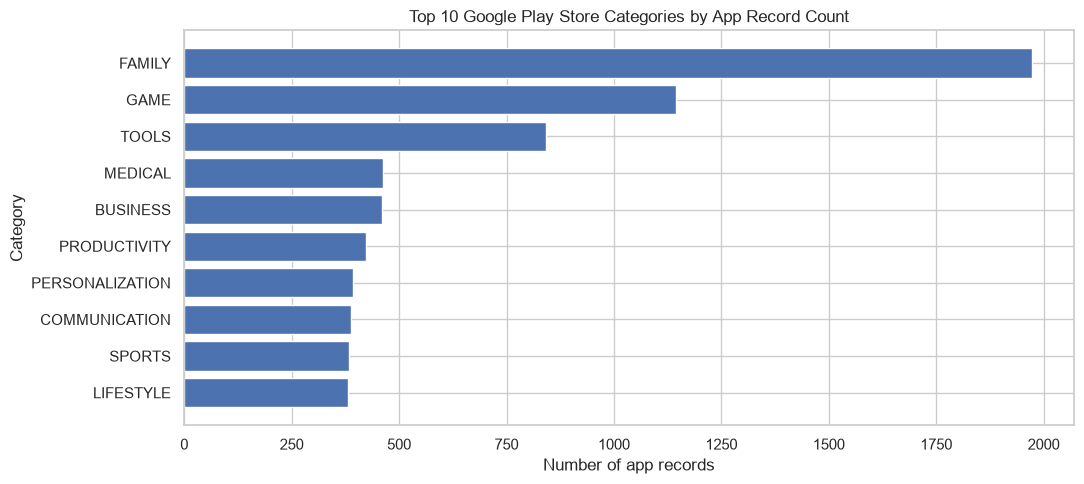

Observation 1: The chart ranks categories by number of records, not by installs or ratings.
Observation 2: The largest category is FAMILY with 1972 records.


In [9]:
top_categories = apps["Category"].value_counts().head(10)
plt.figure(figsize=(11,5))
plt.barh(top_categories.index[::-1], top_categories.values[::-1])
plt.title("Top 10 Google Play Store Categories by App Record Count")
plt.xlabel("Number of app records"); plt.ylabel("Category"); plt.tight_layout(); plt.show()
print("Observation 1: The chart ranks categories by number of records, not by installs or ratings.")
print("Observation 2: The largest category is", top_categories.index[0], "with", int(top_categories.iloc[0]), "records.")

## 8. Pivot tables and cross-tabulation (Task 3)
The pivot table presents average ratings by category and app type. The crosstabulation reports app-record counts across category and content rating. Missing category values are retained where the operation allows it.

In [10]:
pivot_rating = pd.pivot_table(
    apps, index="Category", columns="Type", values="Rating",
    aggfunc="mean", observed=False
)
display(pivot_rating.round(2).head(15))
type_content_crosstab = pd.crosstab(apps["Type"], apps["Content Rating"], margins=True)
display(type_content_crosstab)

Type,0,Free,Paid
Category,,,
1.9,19.0,NaN,NaN
ART_AND_DESIGN,NaN,4.34,4.73
AUTO_AND_VEHICLES,NaN,4.18,4.60
BEAUTY,NaN,4.28,NaN
BOOKS_AND_REFERENCE,NaN,4.35,4.28
BUSINESS,NaN,4.12,4.20
COMICS,NaN,4.16,NaN
COMMUNICATION,NaN,4.17,4.06
DATING,NaN,3.98,3.62


Content Rating,Adults only 18+,Everyone,Everyone 10+,Mature 17+,Teen,Unrated,All
Type,,,,,,,
Free,3,8019,380,479,1156,2,10039
Paid,0,695,33,20,52,0,800
All,3,8714,413,499,1208,2,10839


## 9. Reshaping the data (Task 4)
In wide data, separate measures appear in different columns; in long data, a variable is represented by a name/value pair in rows. `melt()` changes selected columns into long form. `pivot()` can restore a wide layout when each index/column combination is unique. `stack()` and `unstack()` shift levels between the columns and index.

In [11]:
wide_sample = apps[["App","Rating","Reviews_num","Installs_num"]].dropna(subset=["App"]).head(8).copy()
long_sample = wide_sample.melt(id_vars="App", var_name="Measure", value_name="Value")
display(long_sample.head(12))
wide_again = long_sample.pivot(index="App", columns="Measure", values="Value")
display(wide_again)
multi = category_summary[["app_count","mean_rating"]].head(5)
stacked = multi.stack()
display(stacked)
unstacked = stacked.unstack()
display(unstacked)

,App,Measure,Value
0,Photo Editor & Candy Camera & Grid & ScrapBook,Rating,4.1
1,Coloring book moana,Rating,3.9
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Rating,4.7
3,Sketch - Draw & Paint,Rating,4.5
4,Pixel Draw - Number Art Coloring Book,Rating,4.3
5,Paper flowers instructions,Rating,4.4
6,Smoke Effect Photo Maker - Smoke Editor,Rating,3.8
7,Infinite Painter,Rating,4.1
8,Photo Editor & Candy Camera & Grid & ScrapBook,Reviews_num,159.0
9,Coloring book moana,Reviews_num,967.0


Measure,Installs_num,Rating,Reviews_num
App,,,
Coloring book moana,500000.0,3.9,967.0
Infinite Painter,1000000.0,4.1,36815.0
Paper flowers instructions,50000.0,4.4,167.0
Photo Editor & Candy Camera & Grid & ScrapBook,10000.0,4.1,159.0
Pixel Draw - Number Art Coloring Book,100000.0,4.3,967.0
Sketch - Draw & Paint,50000000.0,4.5,215644.0
Smoke Effect Photo Maker - Smoke Editor,50000.0,3.8,178.0
"U Launcher Lite – FREE Live Cool Themes, Hide Apps",5000000.0,4.7,87510.0


Category             
FAMILY    app_count      1972.000000
          mean_rating       4.192272
GAME      app_count      1144.000000
          mean_rating       4.286326
TOOLS     app_count       843.000000
          mean_rating       4.047411
MEDICAL   app_count       463.000000
          mean_rating       4.189143
BUSINESS  app_count       460.000000
          mean_rating       4.121452
dtype: float64

,app_count,mean_rating
Category,,
FAMILY,1972.0,4.192272
GAME,1144.0,4.286326
TOOLS,843.0,4.047411
MEDICAL,463.0,4.189143
BUSINESS,460.0,4.121452


## 10. Combining datasets (Tasks 5 and 6)
### Planned integration
- App data: `googleplaystore.csv`, containing app attributes; `App` is a possible key but is not guaranteed to be unique.
- Review data: `googleplaystore_user_reviews.csv`, containing multiple reviews per app and using `App` as the linking field.
- Relationship: one app can have multiple review records. Summarising reviews by app before joining helps prevent repeated app rows.
- Join options: a left join keeps all app records, an inner join keeps matching records, and an outer join makes unmatched names visible.

The actual review-file integration runs only if the second Kaggle CSV is found beside this notebook. Since the current upload contains only the app CSV, the alternative section is labelled as a demonstration rather than real review analysis.

In [12]:
if os.path.exists(REVIEWS_FILE):
    raw_reviews = pd.read_csv(REVIEWS_FILE)
    reviews = raw_reviews.copy(deep=True)
    print("Review table shape:", reviews.shape)
    print("Review columns:", reviews.columns.tolist())
    display(reviews.head())

    # Aggregate review records to one row per App before integration.
    review_app = reviews.groupby("App", dropna=False).agg(
        review_rows=("App","size"),
        translated_review_count=("Translated_Review","count") if "Translated_Review" in reviews else ("App","size")
    ).reset_index()
    app_key = apps.dropna(subset=["App"]).copy()
    print("App rows before merge:", len(app_key), "unique app keys:", app_key["App"].nunique())
    print("Aggregated review rows:", len(review_app), "unique review app keys:", review_app["App"].nunique())

    merged_left = app_key.merge(review_app, on="App", how="left", indicator=True, validate="many_to_one", suffixes=("_app","_review"))
    print("Left merge shape:", merged_left.shape)
    display(merged_left["_merge"].value_counts())
    merged_inner = app_key.merge(review_app, on="App", how="inner", validate="many_to_one")
    merged_outer = app_key[["App"]].drop_duplicates().merge(review_app[["App"]], on="App", how="outer", indicator=True)
    print("Inner rows:", len(merged_inner), "| outer unique-key rows:", len(merged_outer))
    print("Unmatched app/review keys:")
    display(merged_outer["_merge"].value_counts())

    # join(): demonstrate index-aligned join using unique app-name index.
    app_indexed = app_key.drop_duplicates("App").set_index("App")
    review_indexed = review_app.set_index("App")
    joined_reviews = app_indexed.join(review_indexed, how="left", rsuffix="_review")
    display(joined_reviews.head())

    # concat(): append two labelled halves of the same app-level table.
    app_parts = [app_key.iloc[:len(app_key)//2].assign(source_part="first_half"),
                 app_key.iloc[len(app_key)//2:].assign(source_part="second_half")]
    concatenated_apps = pd.concat(app_parts, axis=0, ignore_index=True)
    print("Concat rows:", len(concatenated_apps), "original rows:", len(app_key))
else:
    print("REAL REVIEW CSV NOT FOUND:", REVIEWS_FILE)
    print("The following is a controlled demonstration only; upload the Kaggle reviews CSV to complete real integration.")
    demo_apps = apps[["App","Category","Rating"]].dropna(subset=["App"]).drop_duplicates("App").head(6).copy()
    demo_reviews = pd.DataFrame({
        "App": demo_apps["App"].head(4).tolist() + ["Controlled demo app not in app table"],
        "Review_Sentiment": ["Positive","Neutral","Negative","Positive","Neutral"]
    })
    demo_reviews_agg = demo_reviews.groupby("App").agg(review_count=("Review_Sentiment","size")).reset_index()
    display(demo_apps.merge(demo_reviews_agg, on="App", how="left", indicator=True))
    # Controlled inner, right and outer join examples
    display(demo_apps.merge(demo_reviews_agg, on="App", how="inner"))
    display(demo_apps.merge(demo_reviews_agg, on="App", how="right"))
    display(demo_apps.merge(demo_reviews_agg, on="App", how="outer", indicator=True))
    # join() aligns on index; concat() appends rows along axis 0.
    display(demo_apps.set_index("App").join(demo_reviews_agg.set_index("App"), how="left", rsuffix="_review"))
    display(pd.concat([demo_apps.head(3), demo_apps.tail(3)], axis=0))

REAL REVIEW CSV NOT FOUND: googleplaystore_user_reviews.csv
The following is a controlled demonstration only; upload the Kaggle reviews CSV to complete real integration.


,App,Category,Rating,review_count,_merge
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,1.0,both
1,Coloring book moana,ART_AND_DESIGN,3.9,1.0,both
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,1.0,both
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,1.0,both
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,NaN,left_only
5,Paper flowers instructions,ART_AND_DESIGN,4.4,NaN,left_only


,App,Category,Rating,review_count
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,1
1,Coloring book moana,ART_AND_DESIGN,3.9,1
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,1
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,1


,App,Category,Rating,review_count
0,Coloring book moana,ART_AND_DESIGN,3.9,1
1,Controlled demo app not in app table,NaN,NaN,1
2,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,1
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,1
4,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,1


,App,Category,Rating,review_count,_merge
0,Coloring book moana,ART_AND_DESIGN,3.9,1.0,both
1,Controlled demo app not in app table,NaN,NaN,1.0,right_only
2,Paper flowers instructions,ART_AND_DESIGN,4.4,NaN,left_only
3,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,1.0,both
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,NaN,left_only
5,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,1.0,both
6,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,1.0,both


/var/folders/6t/6m6yjsl97w767g5x9h9v6n840000gp/T/ipykernel_41827/3083184294.py:52: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(demo_apps.set_index("App").join(demo_reviews_agg.set_index("App"), how="left", rsuffix="_review"))


,Category,Rating,review_count
App,,,
Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,1.0
Coloring book moana,ART_AND_DESIGN,3.9,1.0
"U Launcher Lite – FREE Live Cool Themes, Hide Apps",ART_AND_DESIGN,4.7,1.0
Sketch - Draw & Paint,ART_AND_DESIGN,4.5,1.0
Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,NaN
Paper flowers instructions,ART_AND_DESIGN,4.4,NaN


,App,Category,Rating
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1
1,Coloring book moana,ART_AND_DESIGN,3.9
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3
5,Paper flowers instructions,ART_AND_DESIGN,4.4


### Checking the merge and possible row multiplication
Check key uniqueness and the level of detail in both tables before joining. Since an app can have several reviews, joining every review row directly to the app table can repeat the app information. Grouping reviews by app first creates no more than one review-summary row per app and avoids that multiplication. If the review CSV is unavailable, this check is illustrative only.

In [13]:
print("App table: rows =", len(apps), "| unique App values =", apps["App"].nunique())
print("Duplicate App-name count =", int(apps["App"].duplicated().sum()))
if os.path.exists(REVIEWS_FILE):
    print("Review table: rows =", len(reviews), "| unique App values =", reviews["App"].nunique())
    print("Review table rows per app (top):")
    display(reviews.groupby("App").size().sort_values(ascending=False).head())
else:
    print("Review-table key integrity cannot be assessed until googleplaystore_user_reviews.csv is supplied.")

App table: rows = 10841 | unique App values = 9660
Duplicate App-name count = 1181
Review-table key integrity cannot be assessed until googleplaystore_user_reviews.csv is supplied.


## 11. Descriptive measures (Tasks 7–10)
These calculations use numeric columns parsed from the original fields. Pandas uses the sample convention (`ddof=1`) for variance and standard deviation. Variance is measured in squared units, whereas standard deviation and range use the original variable units.

In [14]:
numeric_vars = ["Rating","Reviews_num","Installs_num","Price_num","Size_MB"]
desc_rows = []
for col in numeric_vars:
    s = apps[col].dropna()
    if len(s) == 0: continue
    mode_values = s.mode()
    desc_rows.append({
        "variable": col, "count": len(s), "mean": s.mean(), "median": s.median(),
        "mode": mode_values.iloc[0] if len(mode_values) else np.nan,
        "variance_sample": s.var(ddof=1), "std_sample": s.std(ddof=1),
        "range": s.max()-s.min(), "min": s.min(), "Q1": s.quantile(.25),
        "Q2_median": s.quantile(.50), "Q3": s.quantile(.75), "max": s.max(),
        "skewness": s.skew(), "excess_kurtosis": s.kurt()
    })
descriptive_table = pd.DataFrame(desc_rows).set_index("variable")
display(descriptive_table.round(3))

,count,mean,median,mode,variance_sample,std_sample,range,min,Q1,Q2_median,Q3,max,skewness,excess_kurtosis
variable,,,,,,,,,,,,,,
Rating,9367,4.193000e+00,4.3,4.4,2.890000e-01,5.370000e-01,1.800000e+01,1.0,4.0,4.3,4.5,1.900000e+01,0.596,65.995
Reviews_num,10840,4.441529e+05,2094.0,0.0,8.571782e+12,2.927761e+06,7.815831e+07,0.0,38.0,2094.0,54775.5,7.815831e+07,16.450,341.060
Installs_num,10840,1.546434e+07,100000.0,1000000.0,7.229992e+15,8.502936e+07,1.000000e+09,0.0,1000.0,100000.0,5000000.0,1.000000e+09,9.572,100.280
Price_num,10840,1.027000e+00,0.0,0.0,2.543930e+02,1.595000e+01,4.000000e+02,0.0,0.0,0.0,0.0,4.000000e+02,23.707,578.143


### Quantiles, percentiles and the five-number summary
The five-number summary consists of the minimum, first quartile, median, third quartile and maximum. The interquartile range (IQR), calculated as Q3 − Q1, represents the spread of the middle half of the observations.

In [15]:
percentile_rows = []
for col in numeric_vars:
    s = apps[col].dropna()
    if len(s):
        percentile_rows.append({
            "variable": col,
            "P10": s.quantile(.10), "P25": s.quantile(.25), "P50": s.quantile(.50),
            "P75": s.quantile(.75), "P90": s.quantile(.90),
            "IQR": s.quantile(.75)-s.quantile(.25)
        })
display(pd.DataFrame(percentile_rows).set_index("variable").round(3))

,P10,P25,P50,P75,P90,IQR
variable,,,,,,
Rating,3.6,4.0,4.3,4.5,4.7,0.5
Reviews_num,3.0,38.0,2094.0,54775.5,464993.1,54737.5
Installs_num,100.0,1000.0,100000.0,5000000.0,10000000.0,4999000.0
Price_num,0.0,0.0,0.0,0.0,0.0,0.0


### Understanding skewness and kurtosis
A positive skew corresponds to a longer right tail, while a negative skew corresponds to a longer left tail. Values closer to zero indicate greater symmetry. Pandas calculates **excess kurtosis**, for which a normal distribution has a reference value near zero. When skewness is substantial, the median and quantiles can be more informative than relying on the mean alone.

In [16]:
display(descriptive_table[["mean","median","skewness","excess_kurtosis"]].round(3))
print("Interpretation guide: compare mean with median and inspect skewness before choosing a typical-value summary.")

,mean,median,skewness,excess_kurtosis
variable,,,,
Rating,4.193000e+00,4.3,0.596,65.995
Reviews_num,4.441529e+05,2094.0,16.450,341.060
Installs_num,1.546434e+07,100000.0,9.572,100.280
Price_num,1.027000e+00,0.0,23.707,578.143


Interpretation guide: compare mean with median and inspect skewness before choosing a typical-value summary.


## 12. Examining distributions (Task 11)
Histograms and box plots help assess the shape of each variable. Descriptions of the real data are based on the plots rather than assuming a normal, skewed or bimodal pattern in advance. Simulated examples are also provided to illustrate shapes that may not be obvious in the app data.

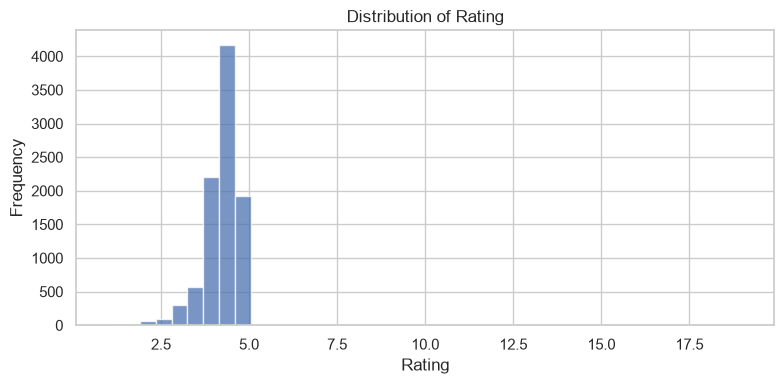

Rating: skewness = 0.596; median = 4.300; mean = 4.193


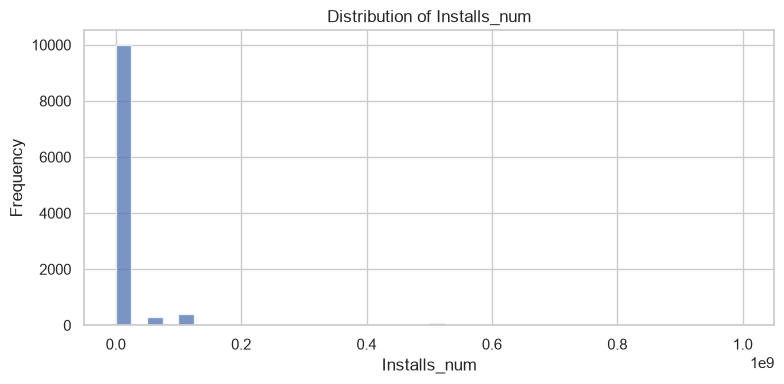

Installs_num: skewness = 9.572; median = 100000.000; mean = 15464338.883


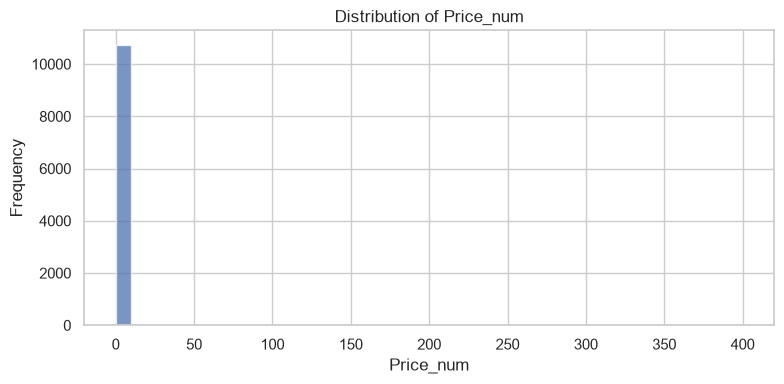

Price_num: skewness = 23.707; median = 0.000; mean = 1.027


In [17]:
for col in ["Rating","Installs_num","Price_num"]:
    s = apps[col].dropna()
    if len(s):
        plt.figure(figsize=(8,4))
        plt.hist(s, bins=40, density=False, alpha=0.75)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()
        print(f"{col}: skewness = {s.skew():.3f}; median = {s.median():.3f}; mean = {s.mean():.3f}")

### Demonstrations using simulated distributions
The arrays in this section are synthetic and are not observations from Google Play. They are included to illustrate approximately normal, positively skewed, negatively skewed and bimodal distributions when the real dataset does not show a clear example.

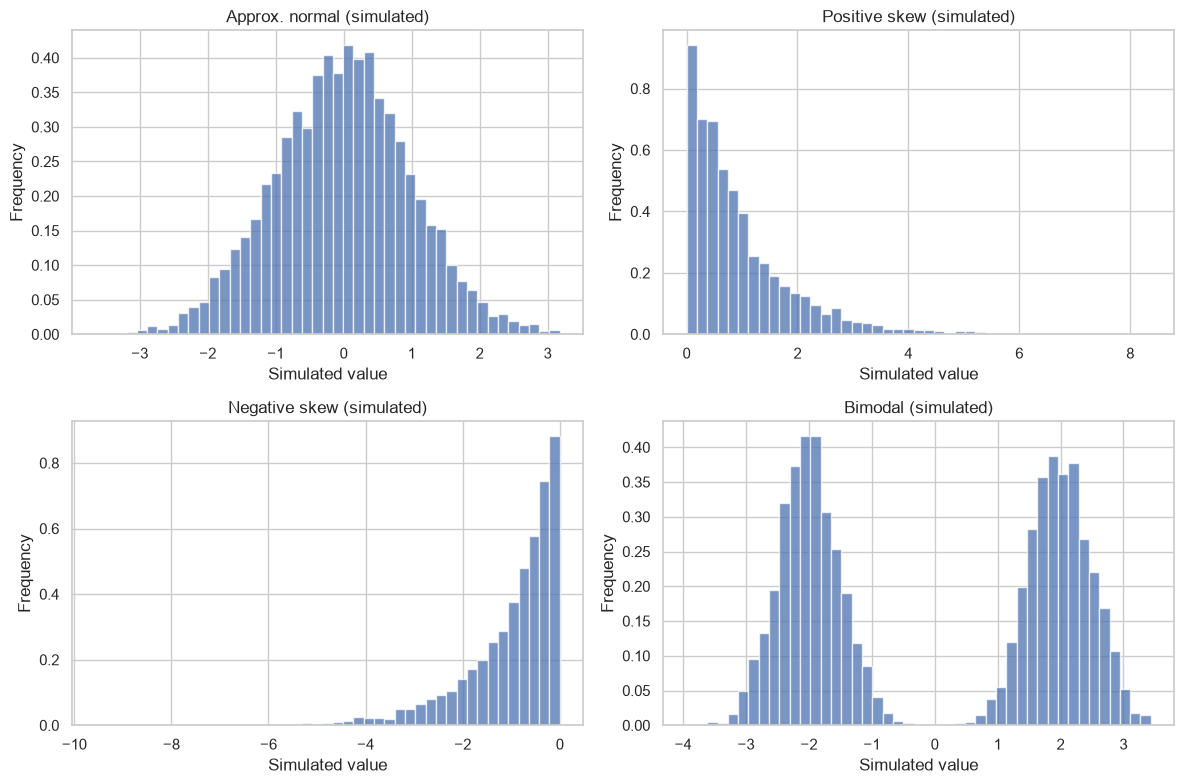

All four panels above are controlled simulations, not original dataset records.


In [18]:
rng = np.random.default_rng(SEED)
simulated = {
    "Approx. normal (simulated)": rng.normal(0, 1, 4000),
    "Positive skew (simulated)": rng.exponential(1, 4000),
    "Negative skew (simulated)": -rng.exponential(1, 4000),
    "Bimodal (simulated)": np.r_[rng.normal(-2, .5, 2000), rng.normal(2, .5, 2000)]
}
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax, (name, values) in zip(axes.flat, simulated.items()):
    ax.hist(values, bins=45, density=True, alpha=0.75)
    ax.set_title(name); ax.set_xlabel("Simulated value"); ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show()
print("All four panels above are controlled simulations, not original dataset records.")

## 13. The empirical rule (Task 12)
The 68–95–99.7 rule is an approximation for a normal, bell-shaped distribution. A suitable real app variable may not follow that shape, so a labelled normal simulation is used for demonstration. The observed proportions for app ratings are also shown as a comparison using real data.

In [19]:
normal_sample = rng.normal(loc=0, scale=1, size=10000)
mu, sigma = normal_sample.mean(), normal_sample.std(ddof=0)
empirical = {}
for k, target in [(1,68), (2,95), (3,99.7)]:
    pct = ((normal_sample >= mu-k*sigma) & (normal_sample <= mu+k*sigma)).mean()*100
    empirical[f"within_{k}_SD"] = {"observed_percent": pct, "rule_percent": target}
display(pd.DataFrame(empirical).T.round(2))
rating = apps["Rating"].dropna()
if len(rating):
    rmu, rsd = rating.mean(), rating.std(ddof=0)
    real_rule = {f"within_{k}_SD": ((rating >= rmu-k*rsd) & (rating <= rmu+k*rsd)).mean()*100 for k in [1,2,3]}
    print("Observed app Rating percentages (real data; rule is not assumed to fit):")
    display(pd.Series(real_rule, name="observed_percent").to_frame().round(2))

,observed_percent,rule_percent
within_1_SD,67.97,68.0
within_2_SD,95.36,95.0
within_3_SD,99.84,99.7


Observed app Rating percentages (real data; rule is not assumed to fit):


,observed_percent
within_1_SD,82.21
within_2_SD,95.30
within_3_SD,98.39


## 14. Sampling and the Central Limit Theorem (Task 13)
For this demonstration, the available app records are considered the source population. Multiple simple random samples are selected without replacement within each repetition, with a fixed random seed for reproducibility. Sample means are plotted for different sample sizes. Under suitable conditions, the CLT explains why the distribution of sample means tends towards normality; increasing sample size generally lowers the variability of those means.

n=10: mean of sample means=4.1996; SD of sample means=0.1728
n=30: mean of sample means=4.1900; SD of sample means=0.0965
n=60: mean of sample means=4.1959; SD of sample means=0.0670


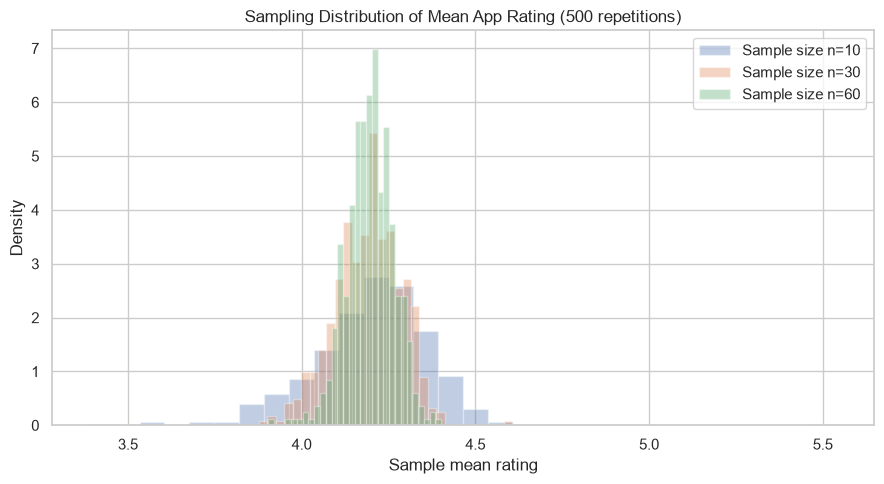

Method: simple random sampling without replacement; repetitions=500; seed=42.


In [20]:
population = apps["Rating"].dropna().to_numpy()
rng_sampling = np.random.default_rng(SEED)
sampling_results = {}
for n in [10, 30, 60]:
    means = [rng_sampling.choice(population, size=n, replace=False).mean() for _ in range(500)]
    sampling_results[n] = means
    print(f"n={n}: mean of sample means={np.mean(means):.4f}; SD of sample means={np.std(means, ddof=1):.4f}")
plt.figure(figsize=(9,5))
for n, means in sampling_results.items():
    plt.hist(means, bins=30, density=True, alpha=0.35, label=f"Sample size n={n}")
plt.title("Sampling Distribution of Mean App Rating (500 repetitions)")
plt.xlabel("Sample mean rating"); plt.ylabel("Density"); plt.legend(); plt.tight_layout(); plt.show()
print("Method: simple random sampling without replacement; repetitions=500; seed=42.")

## 15. Correlation and relationships (Task 14)
Covariance is affected by the units and scale of the variables. Pearson's coefficient describes linear association, whereas Spearman's coefficient measures monotonic association using ranks. The calculations use pairwise complete observations. Neither measure proves a cause-and-effect relationship.

In [21]:
corr_vars = ["Rating","Reviews_num","Installs_num","Price_num","Size_MB"]
corr_data = apps[corr_vars].dropna()
print("Pairwise-complete rows used:", len(corr_data))
display(corr_data.cov().round(3))
display(corr_data.corr(method="pearson").round(3))
display(corr_data.corr(method="spearman").round(3))

Pairwise-complete rows used: 0


/Users/abhinavsinghal/EDA project->2/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:588: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
/Users/abhinavsinghal/EDA project->2/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/Users/abhinavsinghal/EDA project->2/.venv/lib/python3.14/site-packages/pandas/core/frame.py:16733: RuntimeWarning: Degrees of freedom <= 0 for slice
  base_cov = np.cov(mat.T, ddof=ddof)
/Users/abhinavsinghal/EDA project->2/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2902: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/abhinavsinghal/EDA project->2/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2902: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


,Rating,Reviews_num,Installs_num,Price_num,Size_MB
Rating,NaN,NaN,NaN,NaN,NaN
Reviews_num,NaN,NaN,NaN,NaN,NaN
Installs_num,NaN,NaN,NaN,NaN,NaN
Price_num,NaN,NaN,NaN,NaN,NaN
Size_MB,NaN,NaN,NaN,NaN,NaN


,Rating,Reviews_num,Installs_num,Price_num,Size_MB
Rating,NaN,NaN,NaN,NaN,NaN
Reviews_num,NaN,NaN,NaN,NaN,NaN
Installs_num,NaN,NaN,NaN,NaN,NaN
Price_num,NaN,NaN,NaN,NaN,NaN
Size_MB,NaN,NaN,NaN,NaN,NaN


,Rating,Reviews_num,Installs_num,Price_num,Size_MB
Rating,NaN,NaN,NaN,NaN,NaN
Reviews_num,NaN,NaN,NaN,NaN,NaN
Installs_num,NaN,NaN,NaN,NaN,NaN
Price_num,NaN,NaN,NaN,NaN,NaN
Size_MB,NaN,NaN,NaN,NaN,NaN


### Correlation heatmap and scatter plot
The heatmap presents Pearson correlations between numeric fields, and the scatter plot focuses on a pair included in that analysis. Use the plotted points and calculated values to judge direction and strength; avoid interpreting the relationship as causal.

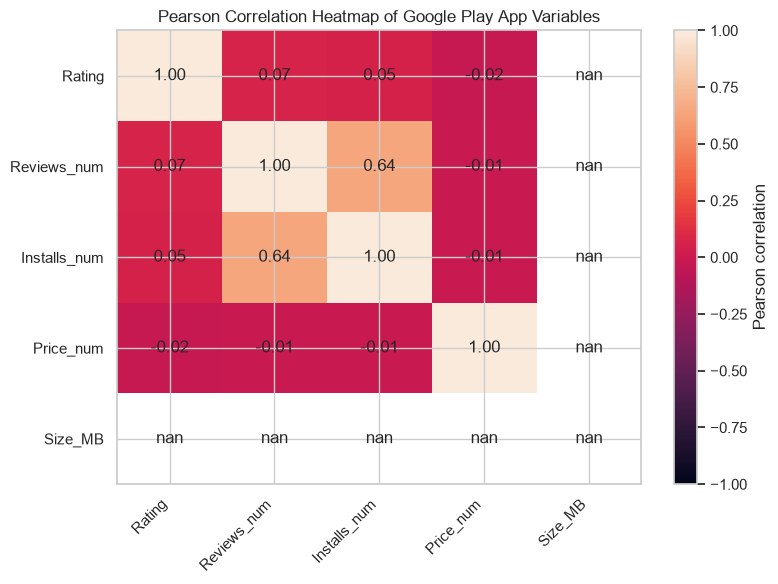

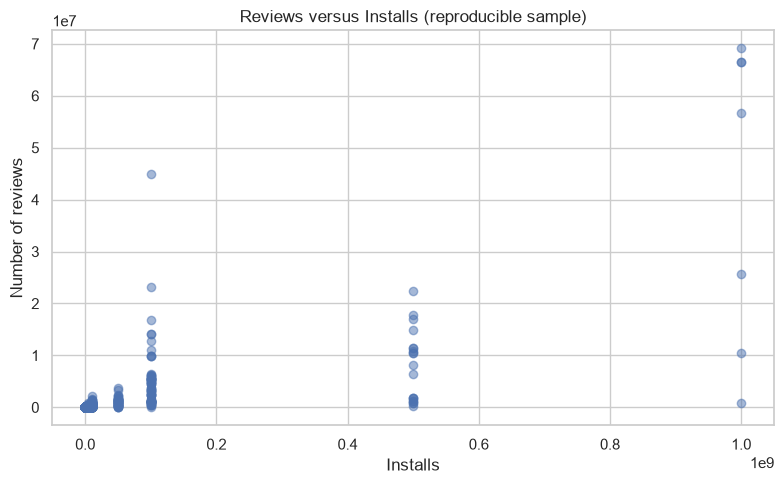

Pearson r: 0.6431


ModuleNotFoundError: No module named 'scipy'

In [22]:
pearson_matrix = apps[corr_vars].corr(method="pearson")
plt.figure(figsize=(8,6))
heat = plt.imshow(pearson_matrix, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(heat, label="Pearson correlation")
plt.xticks(range(len(pearson_matrix.columns)), pearson_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(pearson_matrix.index)), pearson_matrix.index)
for i in range(len(pearson_matrix.index)):
    for j in range(len(pearson_matrix.columns)):
        plt.text(j, i, f"{pearson_matrix.iloc[i,j]:.2f}", ha="center", va="center")
plt.title("Pearson Correlation Heatmap of Google Play App Variables")
plt.tight_layout(); plt.show()

scatter_data = apps[["Reviews_num","Installs_num"]].dropna()
if len(scatter_data):
    sample_scatter = scatter_data.sample(min(2000, len(scatter_data)), random_state=SEED)
    plt.figure(figsize=(8,5))
    plt.scatter(sample_scatter["Installs_num"], sample_scatter["Reviews_num"], alpha=.5)
    plt.title("Reviews versus Installs (reproducible sample)")
    plt.xlabel("Installs"); plt.ylabel("Number of reviews"); plt.tight_layout(); plt.show()
    print("Pearson r:", round(scatter_data["Reviews_num"].corr(scatter_data["Installs_num"], method="pearson"), 4))
    print("Spearman rho:", round(scatter_data["Reviews_num"].corr(scatter_data["Installs_num"], method="spearman"), 4))
print("Correlation indicates association only; it does not prove that installs cause reviews or vice versa.")

## 16. Finding and treating outliers (Tasks 15 and 16)
The IQR limits are calculated as Q1 − 1.5×IQR and Q3 + 1.5×IQR. Z-scores use the sample mean and population standard deviation for the selected variable, with |Z| > 3 used as an exploratory cutoff. The two methods can identify different records, particularly when distributions are skewed. Flagged observations are reviewed before deciding on any treatment.

In [ ]:
outlier_col = "Installs_num"
outlier_series = apps[outlier_col].dropna()
q1, q3 = outlier_series.quantile([.25,.75])
iqr = q3-q1
lower_fence, upper_fence = q1-1.5*iqr, q3+1.5*iqr
iqr_mask = (outlier_series < lower_fence) | (outlier_series > upper_fence)
z_scores = (outlier_series-outlier_series.mean()) / outlier_series.std(ddof=0)
z_mask = z_scores.abs() > 3
outlier_report = pd.DataFrame({
    "method": ["IQR","Z-score |Z| > 3"],
    "threshold": [f"below {lower_fence:.2f} or above {upper_fence:.2f}", "|Z| > 3"],
    "count": [int(iqr_mask.sum()), int(z_mask.sum())],
    "percent_of_nonmissing": [iqr_mask.mean()*100, z_mask.mean()*100]
})
display(outlier_report.round(3))
plt.figure(figsize=(9,4))
plt.boxplot(outlier_series, vert=False)
plt.title("Box Plot of App Installs (potential outliers)")
plt.xlabel("Install count"); plt.tight_layout(); plt.show()
display(apps.loc[iqr_mask.reindex(apps.index, fill_value=False), ["App","Category","Installs","Installs_num"]].head(10))

### Comparing removal, capping and retention
The notebook creates three separate working copies. Removal is included as a sensitivity comparison, not as a default cleaning rule. Capping applies the IQR limits while keeping the rows, whereas retention leaves valid extreme app-popularity values unchanged. Compare the mean, median, standard deviation and range across the versions.

In [ ]:
base = apps[outlier_col].dropna().copy()
removed = base.loc[~iqr_mask].copy()
capped = base.clip(lower=lower_fence, upper=upper_fence)
retained = base.copy()
comparison = pd.DataFrame({
    "Original": [base.mean(),base.median(),base.std(),base.max()-base.min()],
    "Removal_scenario": [removed.mean(),removed.median(),removed.std(),removed.max()-removed.min()],
    "Capping_scenario": [capped.mean(),capped.median(),capped.std(),capped.max()-capped.min()],
    "Retention": [retained.mean(),retained.median(),retained.std(),retained.max()-retained.min()]
}, index=["mean","median","std_sample","range"])
display(comparison.round(2))
print("Decision: retain valid extreme install counts in the primary dataset; use capped/removed copies only for sensitivity comparison.")

## 17. Required charts and interpretation
The notebook produces a histogram, box plot, scatter plot, category-count bar chart, correlation heatmap and sampling-distribution plot. Titles and axis labels are included. The sections below provide space to record at least two observations for each major visualisation.

In [ ]:
print("Histogram observations:")
print("1. Rating is bounded by the rating scale; inspect its skewness and median/mean comparison.")
print("2. Installs and reviews commonly span different magnitudes; use their histograms and skewness values above rather than assuming normality.")
print("\\nBox plot observations:")
print("1. Points beyond the whiskers are potential statistical outliers, not automatically data errors.")
print("2. Install counts are discrete and strongly scale-dependent; extreme popularity may be meaningful.")
print("\\nScatter plot observations:")
print("1. The plotted sample shows the joint pattern between installs and reviews.")
print("2. Pearson and Spearman values above quantify linear and rank association; neither implies causality.")
print("\\nBar chart observations:")
print("1. Categories differ in number of app records.")
print("2. App count is not equivalent to category popularity, quality or user satisfaction.")
print("\\nHeatmap observations:")
print("1. Positive/negative values indicate direction of pairwise linear association.")
print("2. Correlations depend on available complete pairs and do not establish cause-and-effect.")
print("\\nSampling plot observations:")
print("1. Sample means vary across random samples.")
print("2. Compare the reported SDs for n=10, 30 and 60 to observe how variability changes with sample size.")

## 18. Main findings
Base the observations in this section on the tables and charts generated above. Discuss:
- which app categories contain the most records;
- the average and median rating, along with the rating distribution;
- the shapes of the install and review distributions;
- the strongest numeric relationships found;
- missing values, invalid entries, duplicates and key-integrity concerns;
- how many potential outliers are flagged by the IQR and Z-score approaches.

Use the actual notebook outputs for numerical results. Add a brief summary supported by those results before submission.

In [ ]:
print("Top 5 categories by app-record count:")
display(apps["Category"].value_counts().head(5).to_frame("app_records"))
print("Overall rating summary:")
display(apps["Rating"].describe().to_frame("Rating"))
print("Potential outlier counts:")
display(outlier_report)

## 19. Constraints and possible extensions
1. The uploaded file is `googleplaystore.csv`. The separate `googleplaystore_user_reviews.csv` file is required for the actual app/review integration and review-sentiment analysis.
2. App names may not be unique, so repeated names should be checked before app-level interpretation or merging.
3. Fields such as `Size`, `Installs` and `Price` need parsing; values that cannot be converted remain missing in the derived numeric columns.
4. The dataset is a snapshot and may differ from the current Google Play Store.
5. Simulated distribution and empirical-rule sections are controlled examples, not observations from the original app data.
6. Correlation describes association and does not establish causation.

**Further work:** Add the reviews CSV, standardise app-name keys, calculate review sentiment summaries by app, and compare those summaries with app ratings while checking merge cardinality and unmatched keys.

## 20. Conclusion
This notebook carries out the Unit IV and Unit V exploratory analysis workflow on the supplied Google Play Store app data. It retains the original dataset, derives additional features, applies grouping and reshaping, calculates descriptive statistics, explores distributions and sampling, measures correlations, identifies potential outliers and reviews data quality.

**Before submission:** Run every cell in order and retain the outputs. Check the Kaggle licence, and place `googleplaystore_user_reviews.csv` beside the notebook before describing the real two-table integration task as completed.